# Etapa 2: aprofundamento das praças

**Beatriz Babinski** · Projeto em Ciência de Dados V · IBMEC

O notebook `02` escolheu e validou o modelo. O `03` contou o que mudou com o feedback da Loft. **Este aqui olha as
praças já formadas de outros ângulos**, para responder perguntas que o KMeans sozinho não responde:

| Passo | Pergunta | Ferramenta |
| --- | --- | --- |
| 1 | A base de anúncios está tratada direito? E o dono prefere vender ou alugar? | regra de meses estáveis, rendimento do aluguel |
| 2 | Existem grupos naturais nos dados, ou é um contínuo? | DBSCAN e HDBSCAN |
| 3 | Quais cidades são atípicas, e o tratamento pegou elas? | Isolation Forest |
| 4 | Como as praças aparecem num plano? | PCA |
| 5 | Quais variáveis dizem a mesma coisa? | dendrograma de correlação |
| 6 | Dá para explicar cada praça em regras simples? | árvore de decisão, Random Forest, permutação, SHAP |

Tudo é calculado pelo código (`densidade.py`, `visao.py`, `explicacao.py`, `anuncios.py`) e roda com `make poc`.

In [1]:
# ============================================================
# PREPARAÇÃO: liga as ferramentas e acha as pastas do projeto
# ============================================================
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
from ibmecPCDV20261_victor_lucas_beatriz_ravi.poc_clusters import anuncios

TABELAS, FIGURAS, INTERNO = (RAIZ / 'reports' / p for p in ('tables', 'figures', 'interno'))
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

def tabela(nome):
    return pd.read_csv(TABELAS / f'{nome}.csv')

def figura(nome, largura=950):
    display(Image(filename=str(FIGURAS / f'{nome}.png'), width=largura))

base = pd.read_csv(RAIZ / 'data' / 'processed' / 'base_municipios.csv', dtype={'id_municipio': str})
print(len(base), 'municípios,', base['nome_cluster'].nunique(), 'tipos de praça')

687 municípios, 5 tipos de praça


## 1. A base de anúncios tratada, e o rendimento do aluguel

> **O QUE É:** três tratamentos na base de anúncios da Loft antes de usar: (a) só a categoria **residencial** (`apartment_house`); (b) **janela de meses escolhida por regra**; (c) a cidade só conta se aparece em quase todos os meses. Com os preços da própria base calculo o **rendimento do aluguel** (12 meses de aluguel sobre o preço de venda).
>
> **POR QUÊ:** (a) a categoria `apartment_house` já é a soma de apartamento com casa, então somar todas as categorias contava o residencial **em dobro**; (b) a coleta mudou em nov/2024 e tem meses com buraco, e escolher o período no olho não é reprodutível; (c) cidade que aparece num mês e some no outro gera mediana de mentira. O rendimento responde à pergunta do professor: onde alugar rende pouco, o dono tende a vender, e sobra menos espaço para a fiança.
>
> **O QUE OLHAR:** na primeira célula, a prova da dupla contagem. Na segunda, a tabela de meses: `estavel` e `na_janela`. Na terceira, o rendimento mediano por praça e o p-valor.

In [2]:
# Prova da dupla contagem: em toda cidade e mês, apartment_house = apartment + house.
import pandas as pd
arquivos = sorted((RAIZ / 'data' / 'raw').glob(anuncios.PADRAO_ARQUIVO))
if arquivos:
    amostra = pd.read_csv(arquivos[-1], usecols=['snapshot_month', 'normalized_city_seed', 'operation_type',
                                                 'property_type_group', 'n_listings'])
    soma = amostra.pivot_table(index=['snapshot_month', 'normalized_city_seed', 'operation_type'],
                               columns='property_type_group', values='n_listings', aggfunc='sum', fill_value=0)
    iguais = ((soma['apartment'] + soma['house']) == soma['apartment_house']).mean() * 100
    print(f'Combinações em que apartment_house = apartment + house: {iguais:.1f}% de {len(soma):,}'.replace(',', '.'))
else:
    display(Markdown('_Base de anúncios da Loft não está nesta máquina._'))

Combinações em que apartment_house = apartment + house: 100.0% de 36.654


In [3]:
# Regra dos meses estáveis: volume a até 25% da mediana dos 12 meses anteriores e pelo menos 90% das cidades.
# A janela é a sequência mais recente de meses estáveis (no máximo 6). Índice, não volume: o volume é da Loft.
meses_estaveis = INTERNO / '29_anuncios_meses_estaveis.csv'
if meses_estaveis.exists():
    display(pd.read_csv(meses_estaveis).tail(12))

,snapshot_month,indice_volume,cidades_pct_do_maximo,estavel,na_janela
11,2025-10-01,107.4,97.1,True,False
12,2025-11-01,99.8,98.0,True,False
13,2025-12-01,68.0,96.9,False,False
14,2026-01-01,78.1,96.6,True,False
15,2026-02-01,33.7,94.3,False,False
16,2026-03-01,38.8,94.0,False,False
17,2026-04-01,93.0,95.4,True,True
18,2026-05-01,100.9,94.9,True,True
19,2026-06-01,106.2,94.6,True,True
20,2026-07-01,98.9,92.9,True,True


In [4]:
# Rendimento bruto do aluguel por praça (mediana das cidades com pelo menos 20 anúncios de aluguel e de venda).
resumo = INTERNO / '27_anuncios_resumo_do_teste.csv'
por_praca = INTERNO / '26_anuncios_por_praca.csv'
if resumo.exists():
    r = pd.read_csv(resumo).iloc[0]
    rend = pd.read_csv(por_praca)[['nome_cluster', 'com_anuncio_pct', 'rendimento_aluguel_pct_mediana',
                                   'venda_por_aluguel_mediana']]
    display(rend.rename(columns={'com_anuncio_pct': '% cidades com anúncio',
                                 'rendimento_aluguel_pct_mediana': 'rendimento do aluguel ao ano (%)',
                                 'venda_por_aluguel_mediana': 'anúncios de venda por anúncio de aluguel'}))
    print(f"Janela: {r['janela']} ({r['meses_na_janela']} meses) | cidades com anúncio: {r['municipios_com_anuncio']}")
    print(f"Diferença de rendimento entre praças: Kruskal-Wallis p = {r['rendimento_kruskal_p']:.3f}")
else:
    display(Markdown('_Base de anúncios da Loft não está nesta máquina._'))

,nome_cluster,% cidades com anúncio,rendimento do aluguel ao ano (%),anúncios de venda por anúncio de aluguel
0,Praça madura de locação,64.7,5.13,7.11
1,Praça intermediária conectada,57.0,4.93,9.92
2,Praça popular de grande porte,49.7,5.82,7.07
3,Praça em formação,19.5,5.03,8.36
4,Praça sem mercado formal,7.1,5.08,6.93


Janela: 2026-04 a 2026-08 (5 meses) | cidades com anúncio: 305
Diferença de rendimento entre praças: Kruskal-Wallis p = 0.046


**Leitura:** a dupla contagem existia mesmo, em 100% das combinações, e foi corrigida (a ordem das praças não mudou). A
regra escolheu **abr a ago/2026** sozinha. O rendimento do aluguel fica parecido entre as praças (cerca de 5% ao ano) e
a diferença é fraca (p perto de 0,05). O destaque é a **praça intermediária conectada**: menor rendimento e mais anúncio
de venda para cada anúncio de aluguel. Lá o dono tem mais motivo para vender do que para alugar, e a fiança compete com
a venda do imóvel.

## 2. Existem grupos naturais? DBSCAN e HDBSCAN

> **O QUE É:** o DBSCAN procura regiões **densas** de cidades parecidas e chama de **ruído** quem fica isolado. Não preciso dizer quantos grupos quero: ele descobre. O único parâmetro difícil é o raio (eps), escolhido no **joelho** da curva de k-distância. O HDBSCAN é a versão que se adapta sozinha a densidades diferentes.
>
> **POR QUÊ:** o KMeans sempre entrega os k grupos que você pede, mesmo que eles não existam. Se um método que **não** recebe k achar 5 grupos, ótimo; se achar menos, as praças são cortes de um contínuo, e isso muda como a gente defende o modelo.
>
> **O QUE OLHAR:** no gráfico, o eps no joelho. Na tabela, `grupos_encontrados` e `ruido_pct`. No cruzamento, qual praça vira grupo próprio.

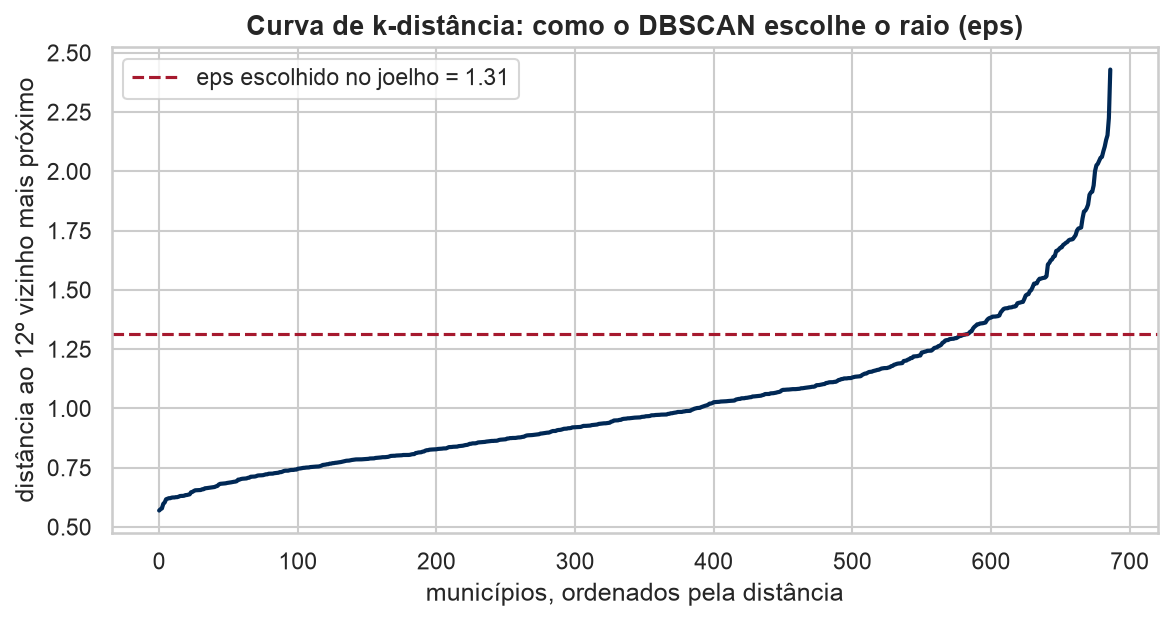

,metodo,parametro,grupos_encontrados,ruido_municipios,ruido_pct,maior_grupo_pct,silhueta_sem_ruido,rand_ajustado_vs_kmeans
0,DBSCAN,"eps = 1.31 (joelho), min_samples = 12",2,23,3.3,88.3,0.451,0.140
1,HDBSCAN,"min_cluster_size = 20, min_samples = 10",2,14,2.0,88.3,0.444,0.139


In [5]:
# Curva de k-distância: distância de cada cidade ao 12º vizinho, em ordem. O joelho é o raio do DBSCAN.
figura('12_k_distancia', 800)
tabela('30_densidade_resumo')

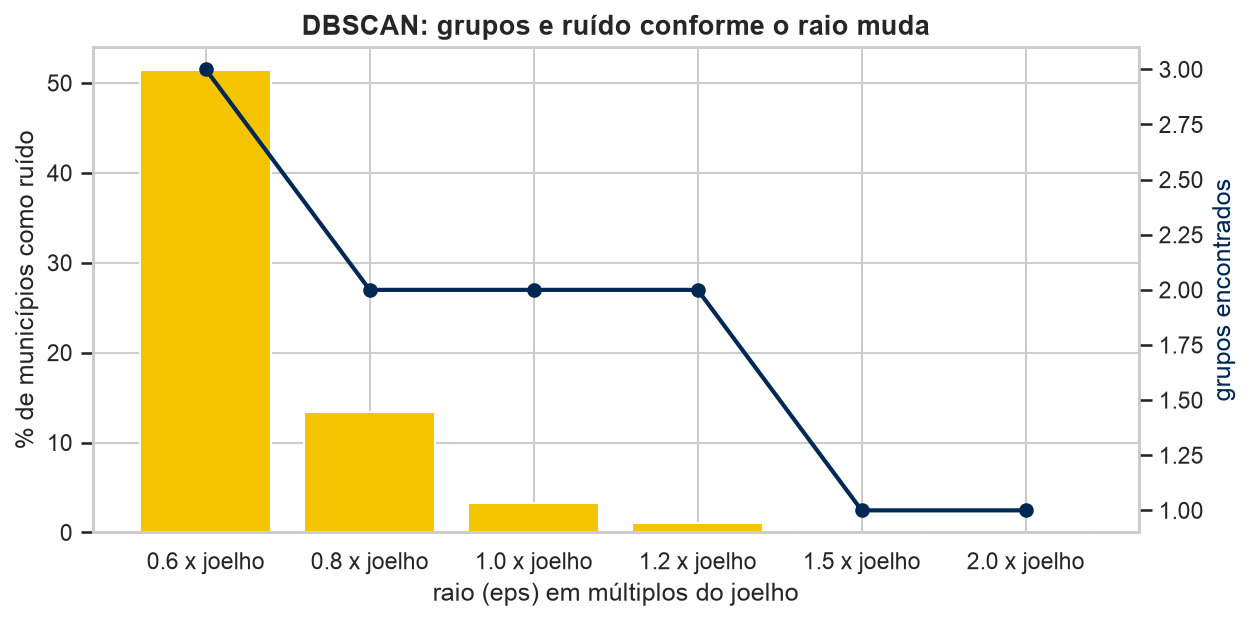

,parametro,grupos_encontrados,ruido_pct,maior_grupo_pct
0,0.6 x joelho,3,51.4,82.0
1,0.8 x joelho,2,13.4,88.6
2,1.0 x joelho,2,3.3,88.3
3,1.2 x joelho,2,1.0,88.1
4,1.5 x joelho,1,0.0,100.0
5,2.0 x joelho,1,0.0,100.0


,nome_cluster,grupo 0,grupo 1,ruído
0,Praça em formação,110,0,3
1,Praça intermediária conectada,213,0,1
2,Praça madura de locação,116,0,3
3,Praça popular de grande porte,155,0,2
4,Praça sem mercado formal,0,79,5


In [6]:
# Sensibilidade: mudando o raio de 0,6 a 2 vezes o joelho, quantos grupos aparecem?
figura('13_dbscan_sensibilidade', 800)
display(tabela('31_densidade_sensibilidade_eps')[['parametro', 'grupos_encontrados', 'ruido_pct', 'maior_grupo_pct']])
# Cruzamento: cada praça do KMeans caiu em qual grupo do HDBSCAN?
tabela('32_densidade_vs_pracas')

**Leitura:** os dois métodos acham **só 2 grupos naturais**: a **praça sem mercado formal** (quase inteira num grupo
próprio) e todo o resto do Brasil num bloco contínuo. Mexendo no raio, nunca aparecem 5 grupos. Isso **confirma** o
achado do notebook 02 (silhueta máxima em k = 2): só a praça sem mercado é separada por natureza; as outras quatro são
**cortes úteis de um contínuo**. Por isso a prova do modelo é ganhar dos baselines, e não "descobrir grupos escondidos".

## 3. Cidades atípicas: Isolation Forest

> **O QUE É:** o Isolation Forest faz cortes aleatórios nos dados e mede quantos cortes são necessários para isolar cada cidade. Cidade atípica se isola rápido e ganha nota alta. Rodei nas 16 variáveis **antes** de aparar os extremos.
>
> **POR QUÊ:** é uma auditoria do tratamento: se as cidades que ele aponta forem as mesmas que a winsorização aparou, o tratamento pegou o problema. Se não forem, sobrou distorção no modelo.
>
> **O QUE OLHAR:** as barras vermelhas (cidades que já tinham sido aparadas) e a porcentagem de concordância.

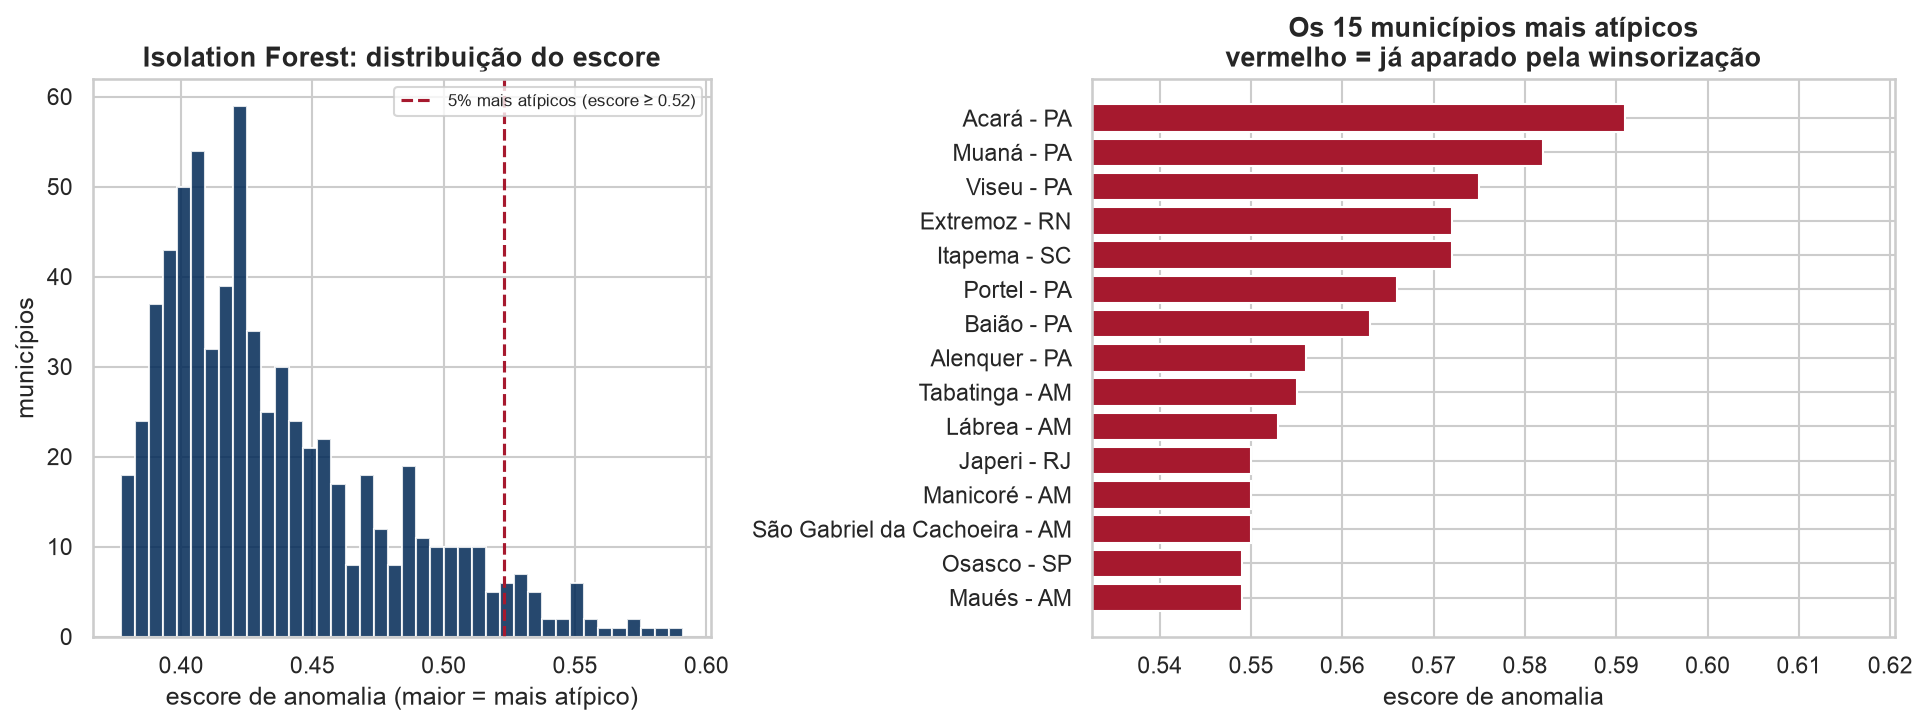

35 cidades marcadas como atípicas (5%); 91% delas já tinham sido aparadas pela winsorização


,municipio,sigla_uf,tipo_de_praca,escore_anomalia,variavel_mais_extrema,aparada_na_winsorizacao
0,Acará,PA,Praça sem mercado formal,0.591,Saldo de emprego / admissões em 12 meses (%),True
1,Muaná,PA,Praça sem mercado formal,0.582,Poupança e depósito a prazo per capita (R$),True
2,Viseu,PA,Praça sem mercado formal,0.575,Poupança e depósito a prazo per capita (R$),True
3,Extremoz,RN,Praça em formação,0.572,Crédito sobre poupança (alavancagem),True
4,Itapema,SC,Praça madura de locação,0.572,Imobiliárias potenciais (CNAE Loft) / 10 mil hab.,True
5,Portel,PA,Praça sem mercado formal,0.566,Admissões de 18 a 30 anos (%),True
6,Baião,PA,Praça sem mercado formal,0.563,Internet móvel 4G/5G de pessoa física / 100 hab.,True
7,Alenquer,PA,Praça sem mercado formal,0.556,Admissões de 18 a 30 anos (%),True
8,Tabatinga,AM,Praça em formação,0.555,Imobiliárias de aluguel ou gestão (%),True
9,Lábrea,AM,Praça sem mercado formal,0.553,Admissões de 18 a 30 anos (%),True


In [7]:
figura('14_cidades_atipicas')
atipicas = tabela('33_cidades_atipicas')
marcadas = atipicas[atipicas['atipica']]
print(f"{len(marcadas)} cidades marcadas como atípicas (5%); "
      f"{marcadas['aparada_na_winsorizacao'].mean():.0%} delas já tinham sido aparadas pela winsorização")
atipicas.head(12)[['municipio', 'sigla_uf', 'tipo_de_praca', 'escore_anomalia', 'variavel_mais_extrema', 'aparada_na_winsorizacao']]

**Leitura:** cerca de 9 em cada 10 cidades atípicas já tinham sido aparadas: o tratamento funcionou. Aparecem dois tipos:
municípios pequenos do Pará e do Amazonas, com crédito, poupança e emprego formal quase nulos; e cidades com efeito
de sede, como **Osasco** (carteira de crédito de banco) e **São Caetano do Sul**, além de **Itapema** (densidade de
imobiliária de cidade de veraneio).

## 4. As praças num plano: PCA

> **O QUE É:** o PCA resume as 6 variáveis do modelo em 2 eixos que guardam o máximo de variação. Cada ponto é uma cidade, o X é o centro da praça e as setas mostram para onde cada variável empurra.
>
> **POR QUÊ:** o modelo trabalha em 6 dimensões, que ninguém consegue ver. O plano dá uma foto aproximada de como as praças se arrumam e mostra quais variáveis criam cada eixo.
>
> **O QUE OLHAR:** a porcentagem de cada eixo, quanto da informação a foto guarda, e a praça sem mercado formal isolada no canto.

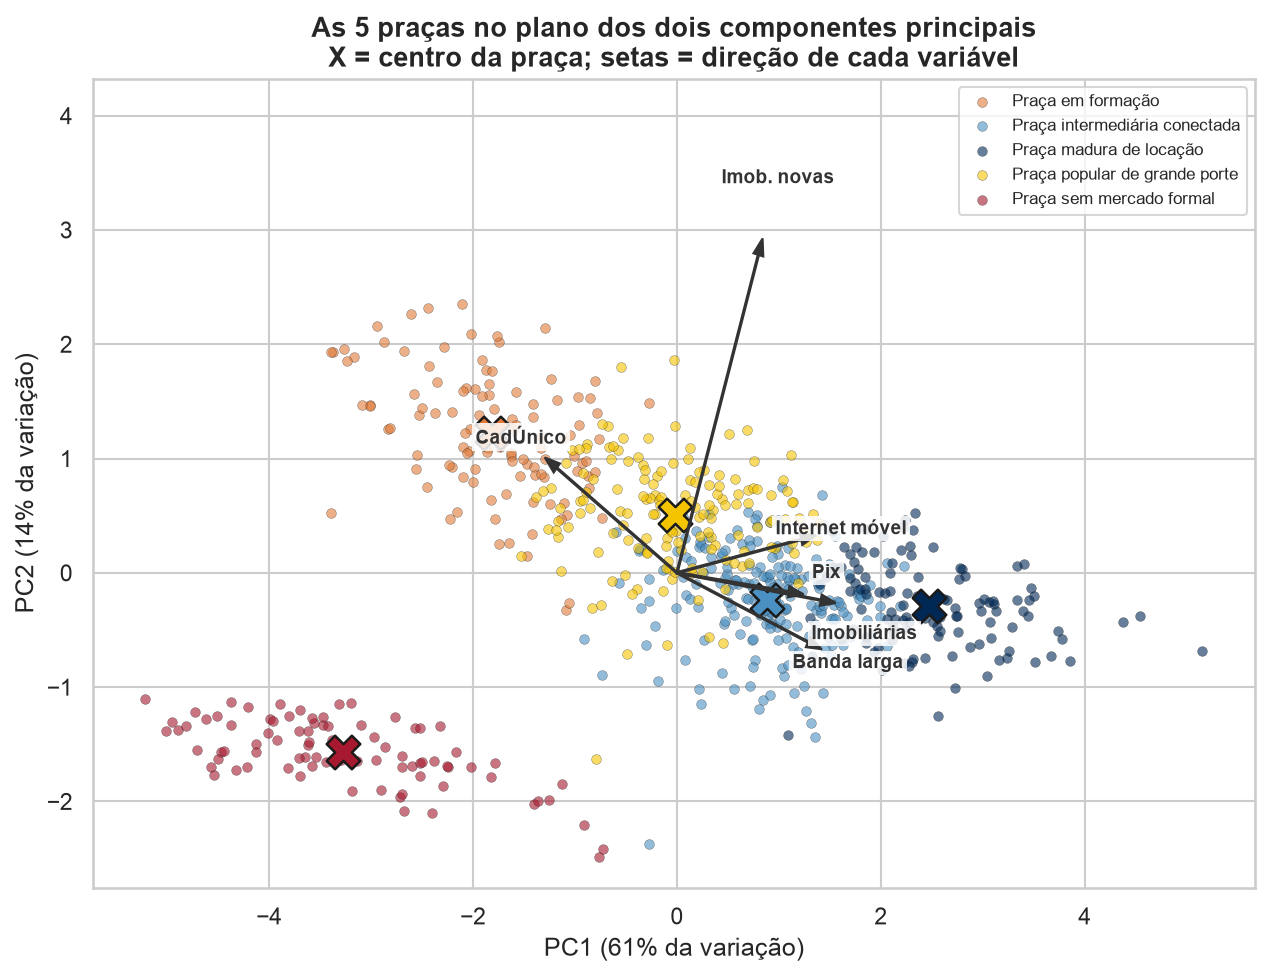

,rotulo,PC1,PC2
0,Imobiliárias potenciais (CNAE Loft) / 10 mil hab.,0.487,-0.083
1,Imobiliárias novas em 12 meses (%),0.263,0.914
2,Pix de pessoa física por habitante,0.388,-0.059
3,Famílias no CadÚnico / 100 domicílios,-0.405,0.315
4,Internet móvel 4G/5G de pessoa física / 100 hab.,0.426,0.102
5,Banda larga fixa / 100 hab.,0.444,-0.209


In [8]:
figura('15_pca_pracas', 800)
cargas = tabela('34_pca_cargas')
cargas[['rotulo', 'PC1', 'PC2']]

**Leitura:** os dois eixos guardam cerca de **75%** da variação. O eixo horizontal é **mercado e renda contra
vulnerabilidade**: praça madura à direita, sem mercado formal à esquerda. O vertical é quase só **imobiliárias abertas
nos últimos 12 meses**, e é ele que levanta a praça em formação. A praça sem mercado formal fica separada, como o DBSCAN
já tinha mostrado. As outras se encostam, porque o Brasil é um contínuo.

## 5. Quais variáveis dizem a mesma coisa? Dendrograma

> **O QUE É:** agrupo as 16 variáveis candidatas pela distância 1 − |correlação de Spearman|. Duas variáveis que se juntam abaixo da linha vermelha (0,20) têm correlação acima de 0,80.
>
> **POR QUÊ:** é outra forma de ver o corte de redundância do notebook 02. A tabela de cortes diz quem saiu; o dendrograma mostra a família inteira de cada variável.
>
> **O QUE OLHAR:** os galhos coloridos abaixo da linha: são os pares que cortamos.

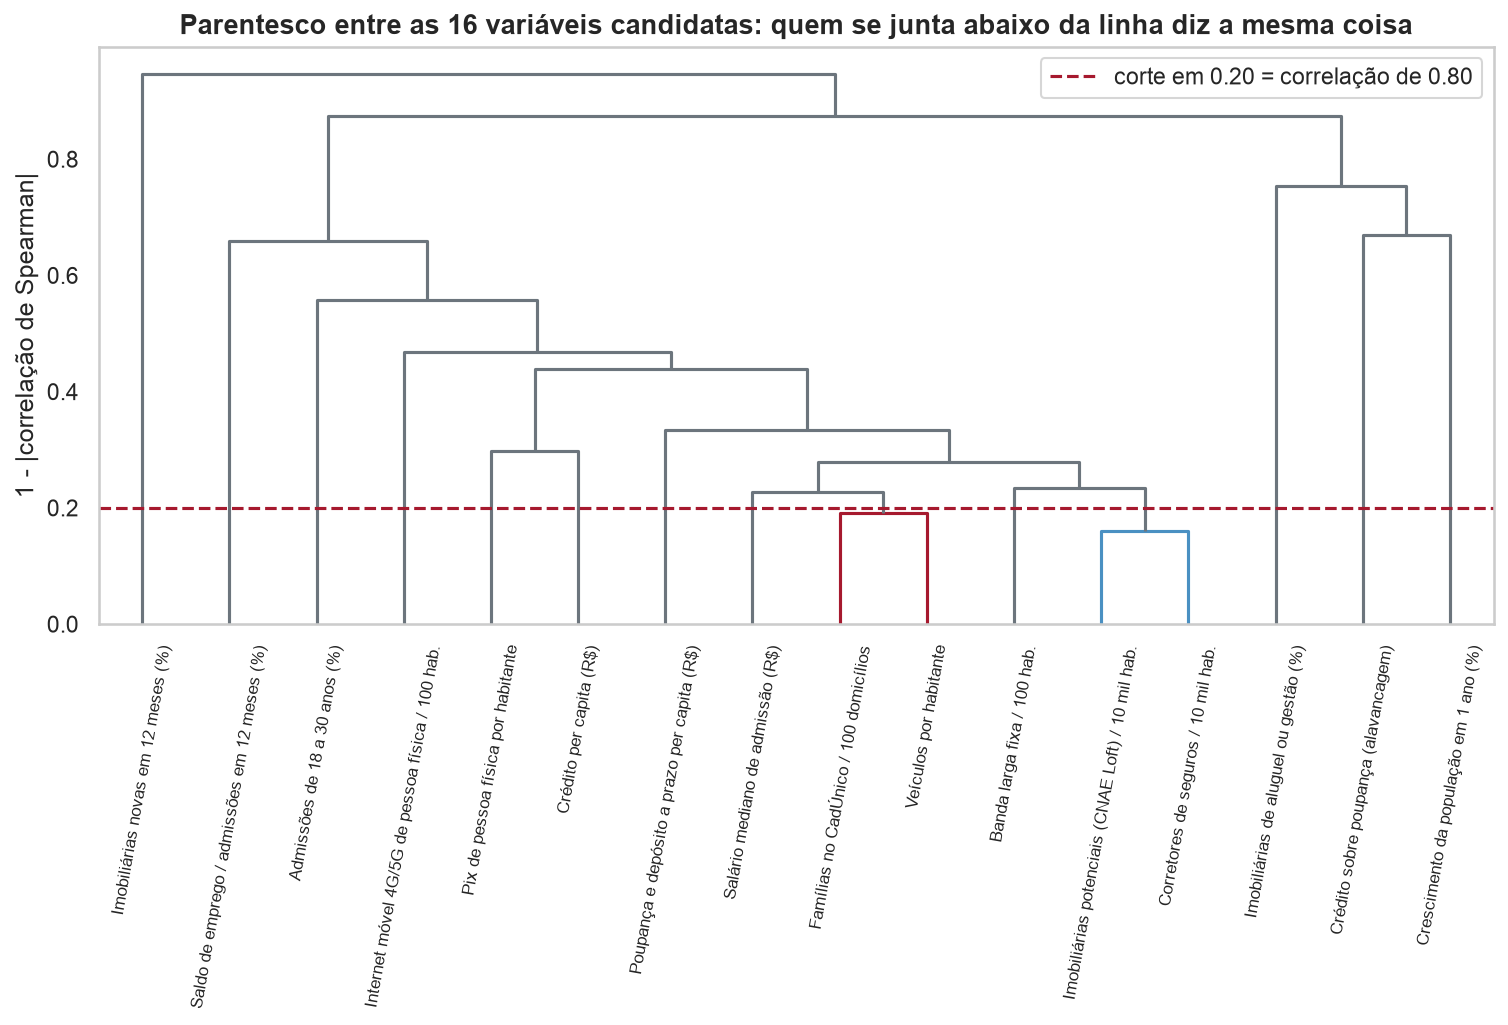

,grupo_redundancia,rotulo
2,3,Famílias no CadÚnico / 100 domicílios
3,3,Veículos por habitante
5,5,Corretores de seguros / 10 mil hab.
6,5,Imobiliárias potenciais (CNAE Loft) / 10 mil hab.


In [9]:
figura('16_dendrograma_variaveis')
par = tabela('35_parentesco_variaveis')
par[par['redundante_com_outra']][['grupo_redundancia', 'rotulo']]

**Leitura:** só dois pares passam do limite: CadÚnico com veículos por habitante, e imobiliárias (CNAE Loft) com corretores
de seguros. São exatamente as duas variáveis que saíram do modelo. O resto se junta bem acima da linha, ou seja, cada
variável que ficou traz informação própria.

## 6. Dá para explicar cada praça em regras simples?

> **O QUE É:** transformo a praça em resposta e treino modelos supervisionados para adivinhá-la a partir das 6 variáveis: uma **árvore de decisão rasa** (3 perguntas), um **Random Forest** e, como baseline, um modelo que sempre chuta a praça mais comum. Tudo com **validação cruzada estratificada de 5 folds**: cada cidade é prevista por um modelo que não a viu.
>
> **POR QUÊ:** a Loft não vai rodar KMeans para classificar uma cidade nova. Uma árvore rasa vira **regra de bolso** com valores reais ('mais de 10 imobiliárias por 10 mil hab. e internet acima de 96 por 100 hab. = praça madura'). A importância por permutação e o SHAP mostram qual variável pesa em cada praça.
>
> **O QUE OLHAR:** o acerto balanceado contra o baseline, a matriz de confusão (onde a árvore erra) e as regras.

In [10]:
# Validação cruzada: acerto e acerto balanceado (média do acerto de cada praça, para praça grande não dominar).
tabela('36_explicacao_validacao_cruzada')

,modelo,acuracia,acuracia_balanceada,acuracia_desvio_entre_folds
0,Baseline: sempre a praça mais comum,0.311,0.200,0.004
1,Árvore de decisão (profundidade 3),0.801,0.800,0.023
2,Random Forest (300 árvores),0.934,0.933,0.015


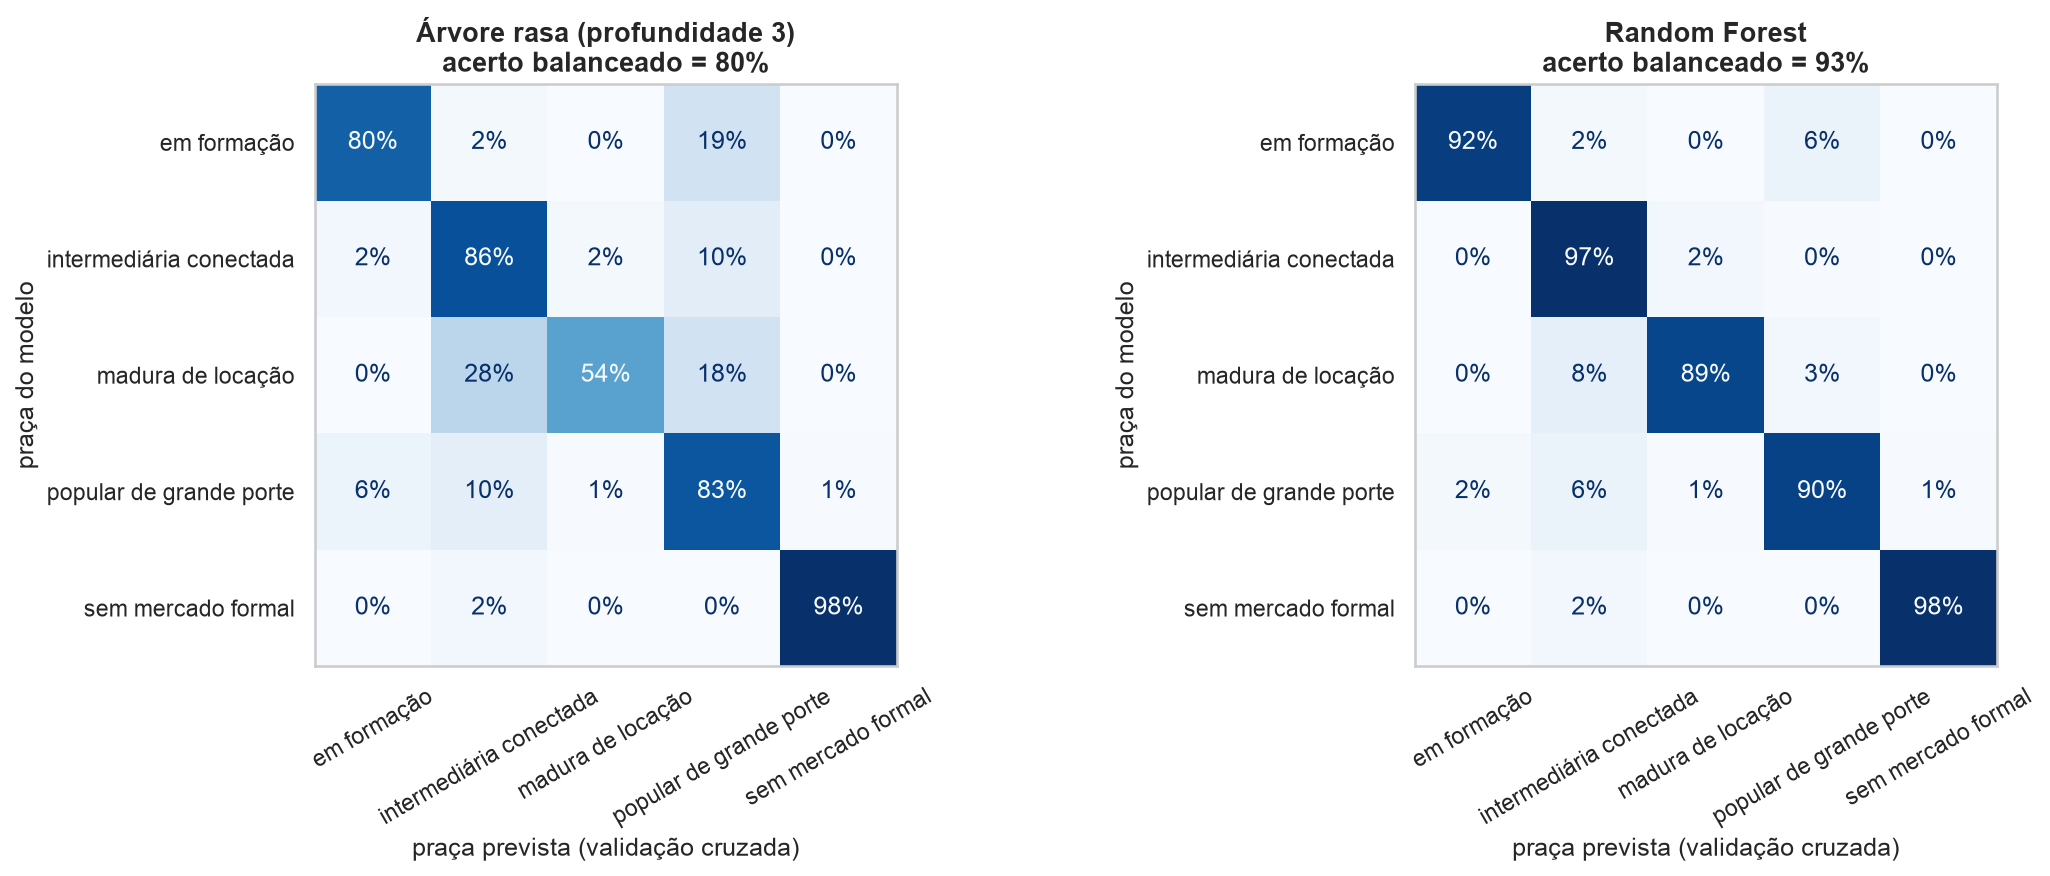

In [11]:
# Matriz de confusão: linha = praça do modelo, coluna = praça prevista. A diagonal é o acerto.
figura('17_matriz_confusao_pracas')

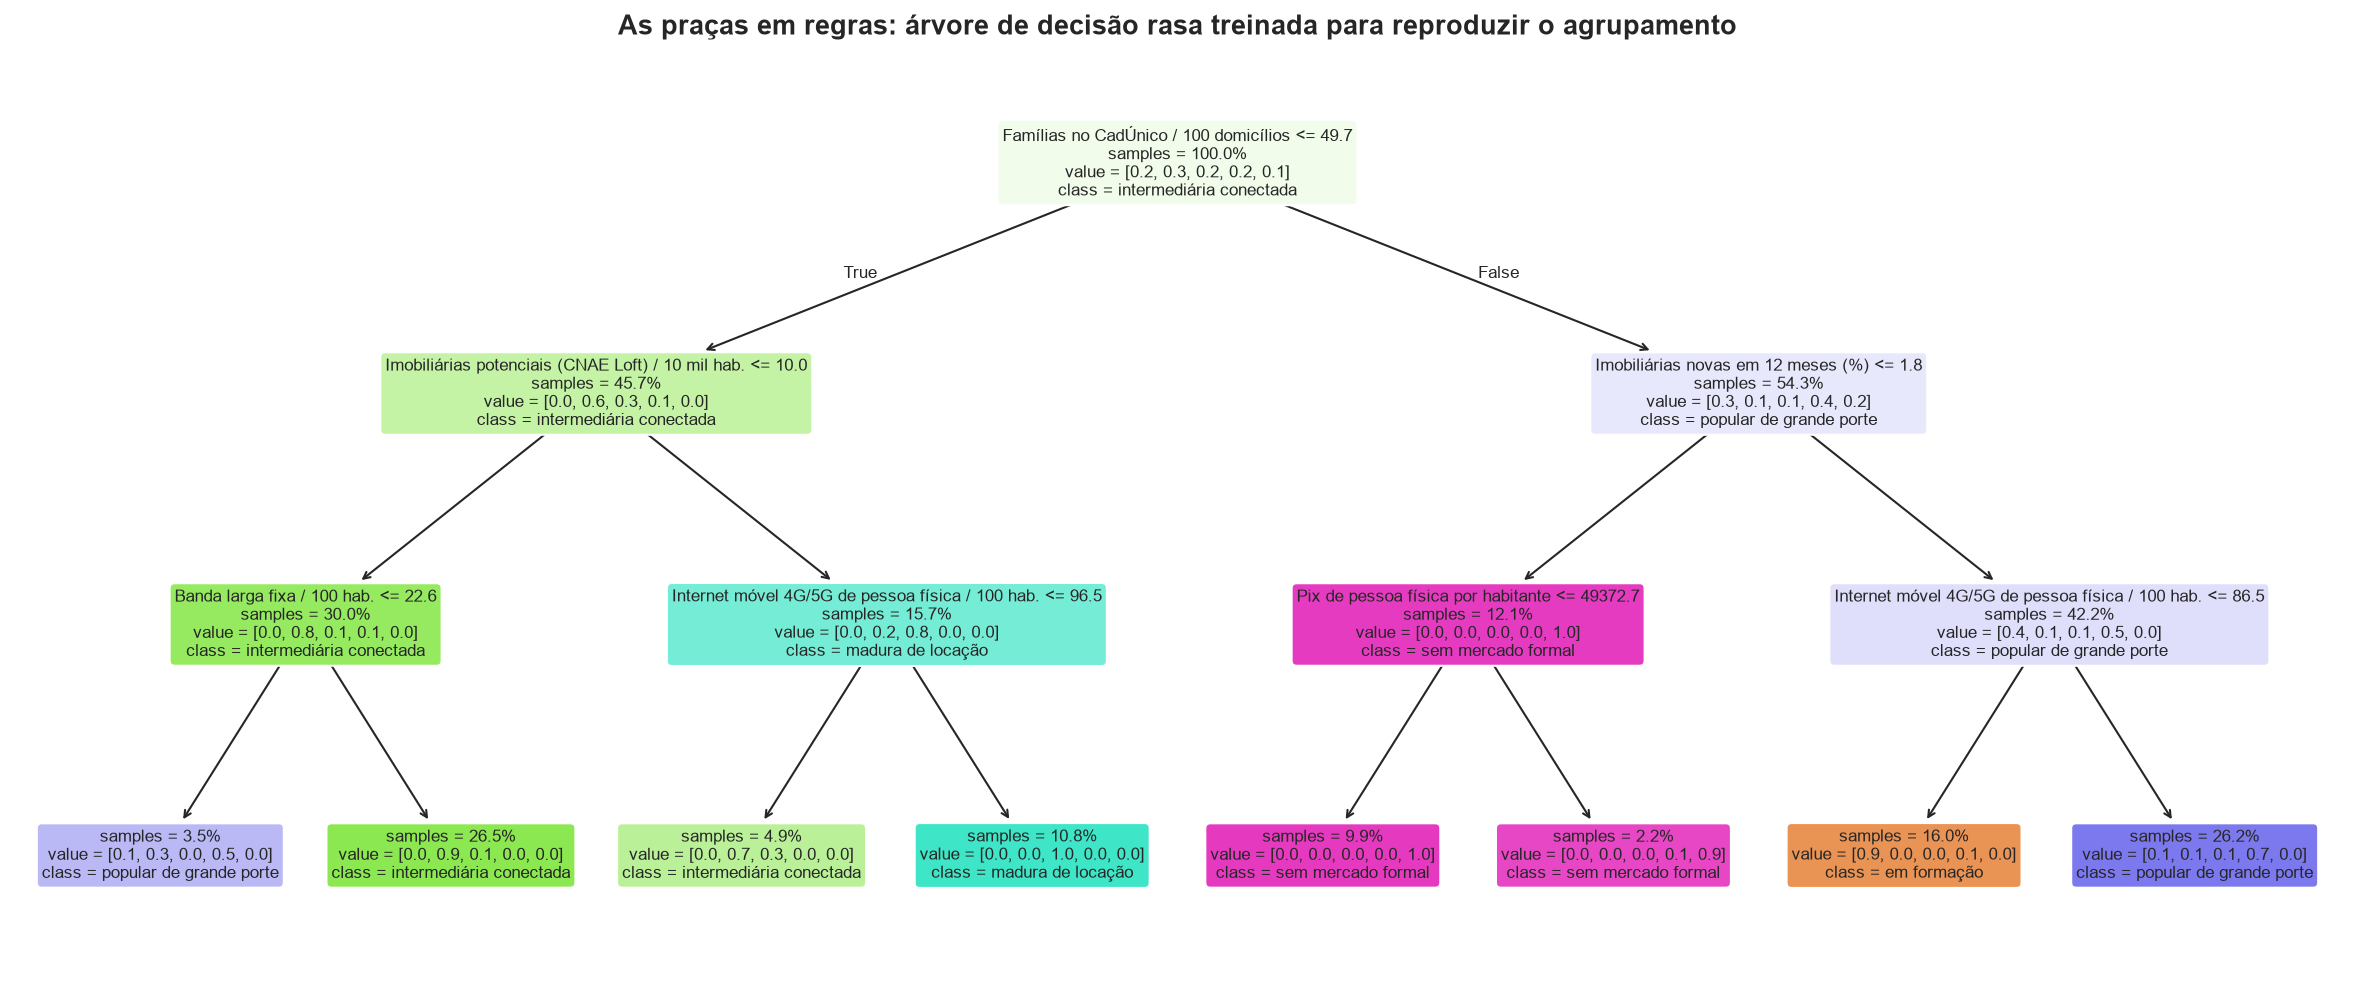

|--- Famílias no CadÚnico / 100 domicílios <= 49.7
|   |--- Imobiliárias potenciais (CNAE Loft) / 10 mil hab. <= 10.0
|   |   |--- Banda larga fixa / 100 hab. <= 22.6
|   |   |   |--- class: Praça popular de grande porte
|   |   |--- Banda larga fixa / 100 hab. >  22.6
|   |   |   |--- class: Praça intermediária conectada
|   |--- Imobiliárias potenciais (CNAE Loft) / 10 mil hab. >  10.0
|   |   |--- Internet móvel 4G/5G de pessoa física / 100 hab. <= 96.5
|   |   |   |--- class: Praça intermediária conectada
|   |   |--- Internet móvel 4G/5G de pessoa física / 100 hab. >  96.5
|   |   |   |--- class: Praça madura de locação
|--- Famílias no CadÚnico / 100 domicílios >  49.7
|   |--- Imobiliárias novas em 12 meses (%) <= 1.8
|   |   |--- Pix de pessoa física por habitante <= 49372.7
|   |   |   |--- class: Praça sem mercado formal
|   |   |--- Pix de pessoa física por habitante >  49372.7
|   |   |   |--- class: Praça sem mercado formal
|   |--- Imobiliárias novas em 12 meses (%) >  1.

In [12]:
# As regras da árvore rasa, em valores reais (é o que a Loft pode usar direto).
figura('18_arvore_regras_pracas', 1000)
print((TABELAS / '39_regras_da_arvore.txt').read_text(encoding='utf-8'))

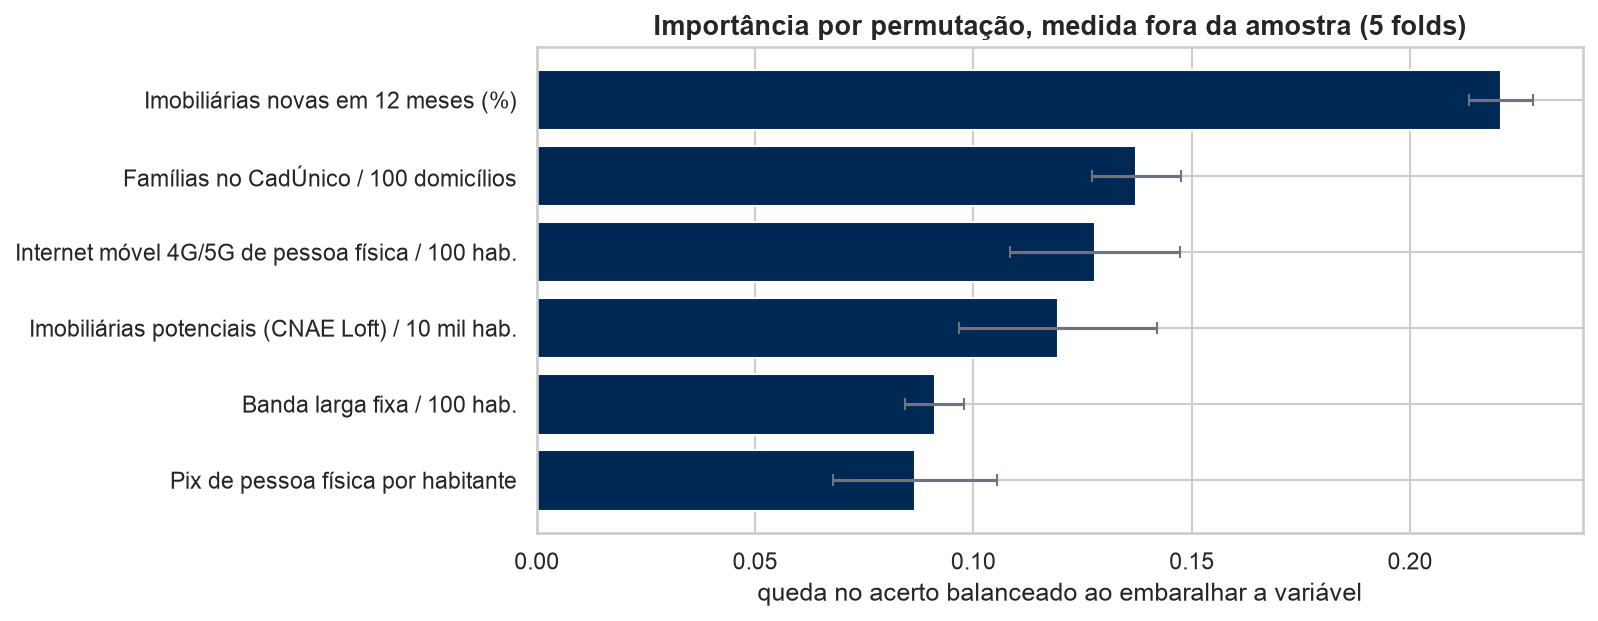

,rotulo,queda_media_acuracia,desvio_entre_folds
0,Imobiliárias novas em 12 meses (%),0.2209,0.0073
1,Famílias no CadÚnico / 100 domicílios,0.1373,0.0102
2,Internet móvel 4G/5G de pessoa física / 100 hab.,0.1278,0.0194
3,Imobiliárias potenciais (CNAE Loft) / 10 mil hab.,0.1194,0.0226
4,Banda larga fixa / 100 hab.,0.0911,0.0067
5,Pix de pessoa física por habitante,0.0867,0.0188


In [13]:
# Importância por permutação, medida FORA da amostra: quanto o acerto cai quando embaralho a variável.
figura('21_importancia_permutacao', 750)
tabela('37_importancia_permutacao')[['rotulo', 'queda_media_acuracia', 'desvio_entre_folds']]

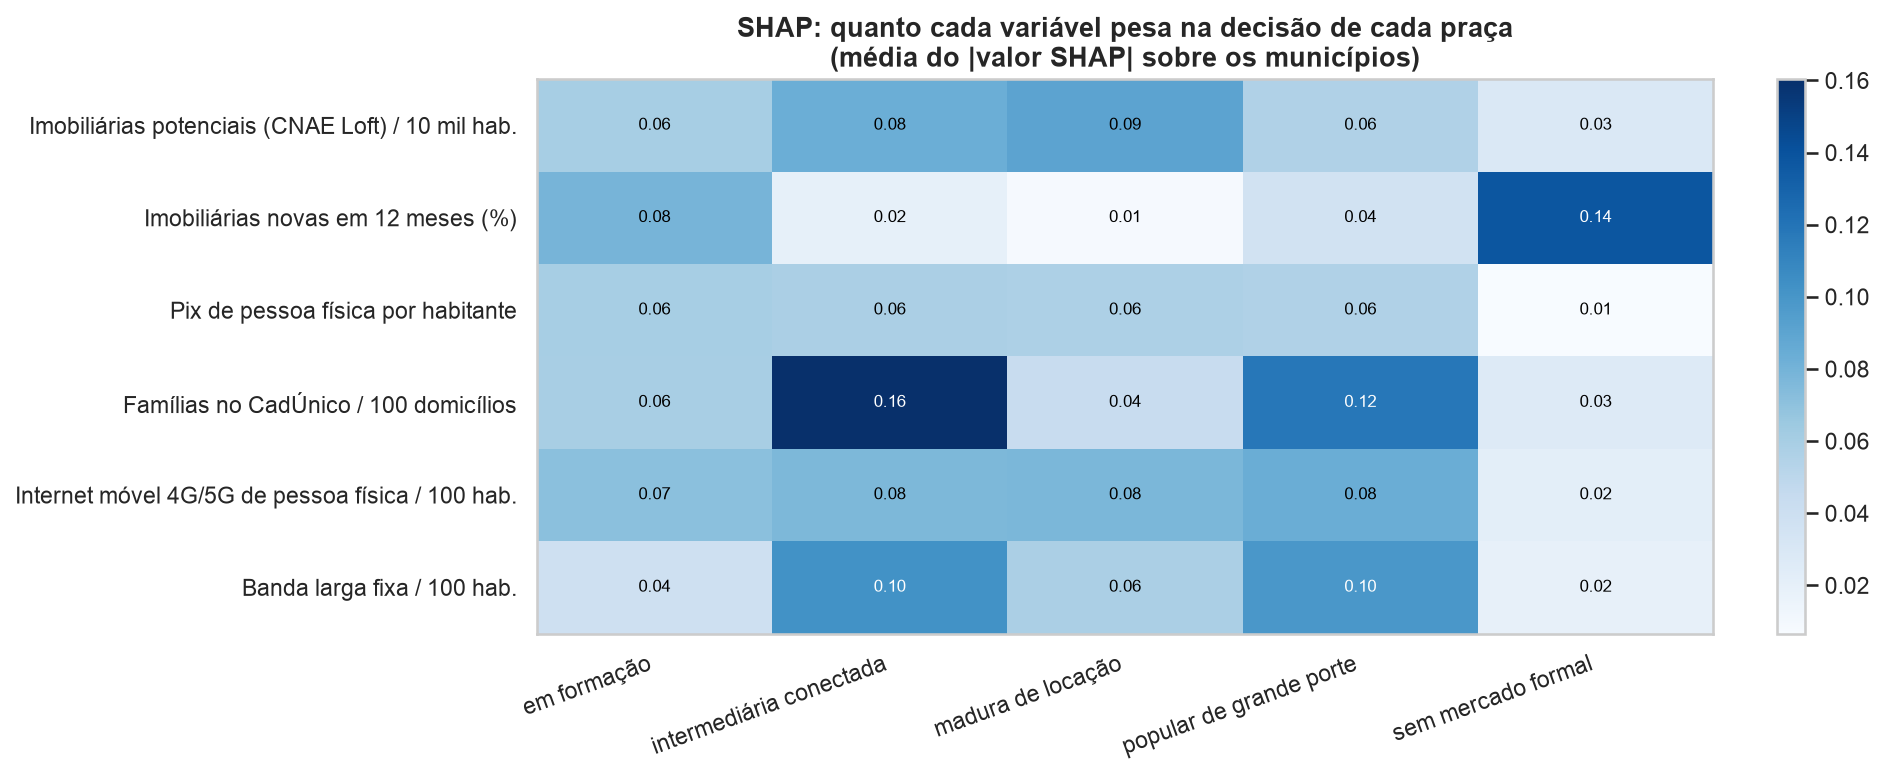

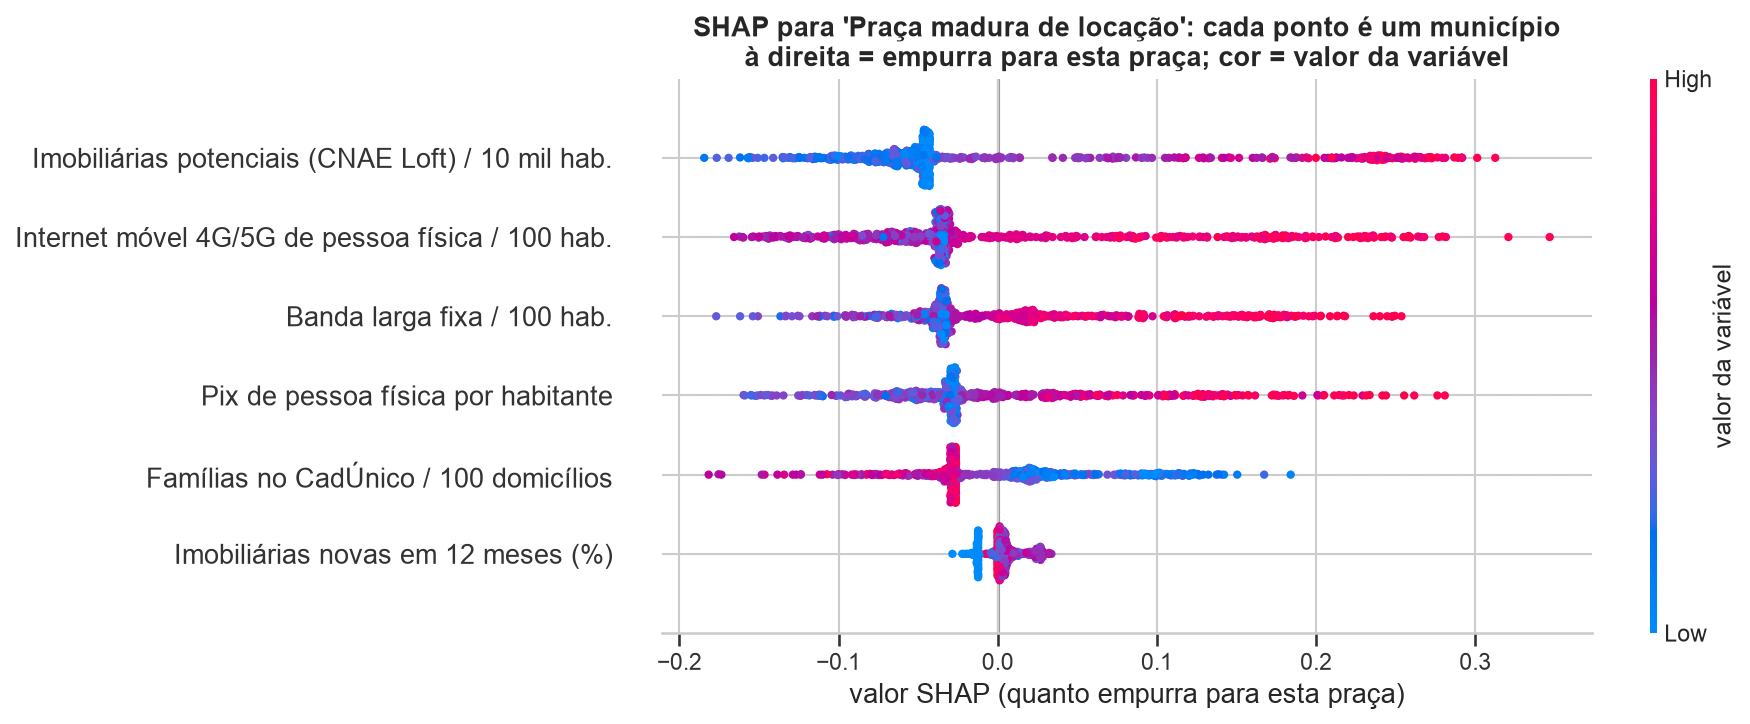

In [14]:
# SHAP: quanto cada variável pesa em cada praça (esquerda) e, para a praça madura, cidade a cidade (direita).
figura('19_shap_por_praca', 850)
figura('20_shap_praca_madura', 850)

**Leitura:**

- A **árvore rasa acerta cerca de 80%** (acerto balanceado), contra 20% do baseline. O **Random Forest acerta cerca de
  93%**. Ou seja, as praças têm regra simples e dá para classificar uma cidade nova sem rodar o modelo.
- A árvore erra mais na **praça madura**, que confunde com a intermediária. Faz sentido: as duas estão lado a lado no
  contínuo do PCA.
- **Imobiliárias novas** é a variável que mais pesa no geral, porque é a única que separa a praça em formação. Para a
  praça madura, o SHAP mostra que o que empurra é ter **muitas imobiliárias, internet e Pix altos e CadÚnico baixo**.
- **Atenção:** isto não é previsão de desempenho. O modelo aprende a reproduzir o agrupamento, e não a acertar vendas.
  Prever MQL e custo é o próximo passo, quando chegarem os dados da Loft.

## O que esta etapa acrescenta ao projeto

| Pergunta | Resposta |
| --- | --- |
| A base de anúncios estava certa? | Não: contava o residencial em dobro. Corrigido, e a janela agora é escolhida por regra. |
| O dono prefere vender ou alugar? | O rendimento do aluguel é parecido entre as praças (cerca de 5% ao ano); a intermediária conectada é onde vender compete mais. |
| As 5 praças são naturais? | Só a sem mercado formal. As outras 4 são cortes úteis de um contínuo, e por isso a prova é o baseline. |
| O tratamento de extremos funcionou? | Sim: 9 em cada 10 cidades atípicas já tinham sido aparadas. |
| Dá para usar sem rodar o modelo? | Sim: 3 perguntas classificam 80% das cidades corretamente. |